In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [17]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def load_txt_file(rootpath, model_name):
    txt_path = os.path.join(rootpath, model_name, "scores.txt")
    if not os.path.exists(txt_path):
        raise FileNotFoundError(f"File not found: {txt_path}")

    scores = []
    labels = []
    with open(txt_path, 'r') as fh:
        for line in fh:
            parts = line.strip().split()
            if len(parts) != 3:
                continue  # skip malformed lines

            _, score, label = parts
            score = score.strip("[]")
            scores.append(float(score))
            labels.append(int(label))

    scores = np.array(scores)
    labels = np.array(labels)
    return scores, labels

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    
def plot_scores_distribution(scores, labels):
    # Split real/fake
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    print(f"Loaded {len(scores)} samples")
    print(f"Real mean score: {real_scores.mean():.4f}")
    print(f"Fake mean score: {fake_scores.mean():.4f}\n")

    # Plot
    plt.figure(figsize=(6, 4))
    plt.hist(real_scores, bins=100, alpha=0.5, density=True)
    plt.hist(fake_scores, bins=100, alpha=0.5, density=True)
    plt.xlabel("Score")
    plt.ylabel("Density")
    plt.title(f"Score Distribution")
    plt.legend(["Real (0)", "Fake (1)"])
    plt.show()

def plot_expert_stats(rootpath,
                      model_name,
                      stat="gating",
                      expert_labels=None):

    base_path = os.path.join(rootpath, model_name)

    global_path = os.path.join(base_path, f"{stat}_mean_global.npy")
    real_path   = os.path.join(base_path, f"{stat}_mean_real.npy")
    spoof_path  = os.path.join(base_path, f"{stat}_mean_fake.npy")

    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    if expert_labels is not None:
        n_experts = len(expert_labels)
        if len(global_w) != n_experts:
            raise ValueError(
                f"Mismatch: loaded stats have {len(global_w)} experts "
                f"but expert_labels has {n_experts}")
    else:
        n_experts = len(global_w)
        expert_labels = [f"E{i}" for i in range(n_experts)]

    fig, axes = plt.subplots(1, 3, figsize=(4*n_experts/2 + 6, 4), sharey=True)

    if stat == "gating":
        fig.suptitle("Gating Weights")
    elif stat == "weighted":
        fig.suptitle("Gating × Expert Logits")
    else:
        fig.suptitle("Expert Logits")

    titles = ["Avg global", "Avg real", "Avg fake"]
    data   = [global_w, real_w, spoof_w]
    colors = ["blue", "pink", "green"]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(n_experts), weights, color=color)
        ax.set_title(title)
        ax.set_xticks(range(n_experts))
        ax.set_xticklabels(expert_labels, rotation=45)
        if stat == 'gating':
            ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    return data


In [18]:
def compute_res_and_plot(rootpath, model_name, expert_labels, distr=False, plot=True):
    scores, labels = load_txt_file(rootpath, model_name)
    
    print("\nIndividual Experts' Performance:")
    experts_scores = np.load(os.path.join(rootpath, model_name, "expert_all.npy"))
    for i in range(experts_scores.shape[1]):
        print_metrics(experts_scores[:, i], labels)    
    print("\nMoE Performance:")
    print_metrics(scores, labels)

    if distr:
        plot_scores_distribution(scores, labels)
        
    if plot:
        out_e = plot_expert_stats(rootpath, model_name, stat= 'expert', expert_labels=expert_labels)
        out_g = plot_expert_stats(rootpath, model_name, stat= 'gating', expert_labels=expert_labels)
        out_w = plot_expert_stats(rootpath, model_name, stat= 'weighted', expert_labels=expert_labels)
        return out_e, out_g, out_w

# Best model so far
- 5 experts
- Frozen
- Trained using W x L (LOGITS)
- BCE loss (1) + attribution loss (0.2)
- Temperature = 1
- lr 1e-3 (scheduler CosineAnn, eta_min 1e-5)
- best val loss (though best model after 1 epoch)
- batch size 64
- win len (when needed) 3 seconds



Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 64.34%, EER: 41.87%

MoE Performance:
AUC: 73.45%, EER: 32.60%
Loaded 19171 samples
Real mean score: -6.6696
Fake mean score: -3.3812



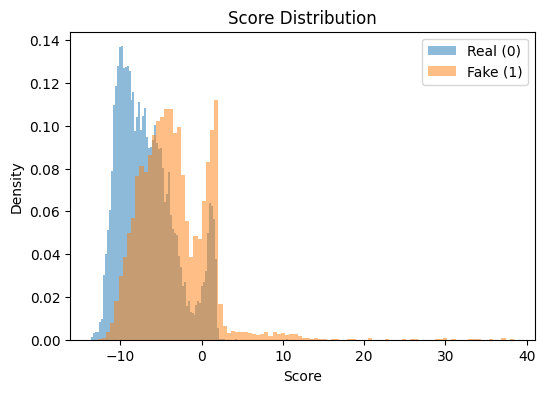

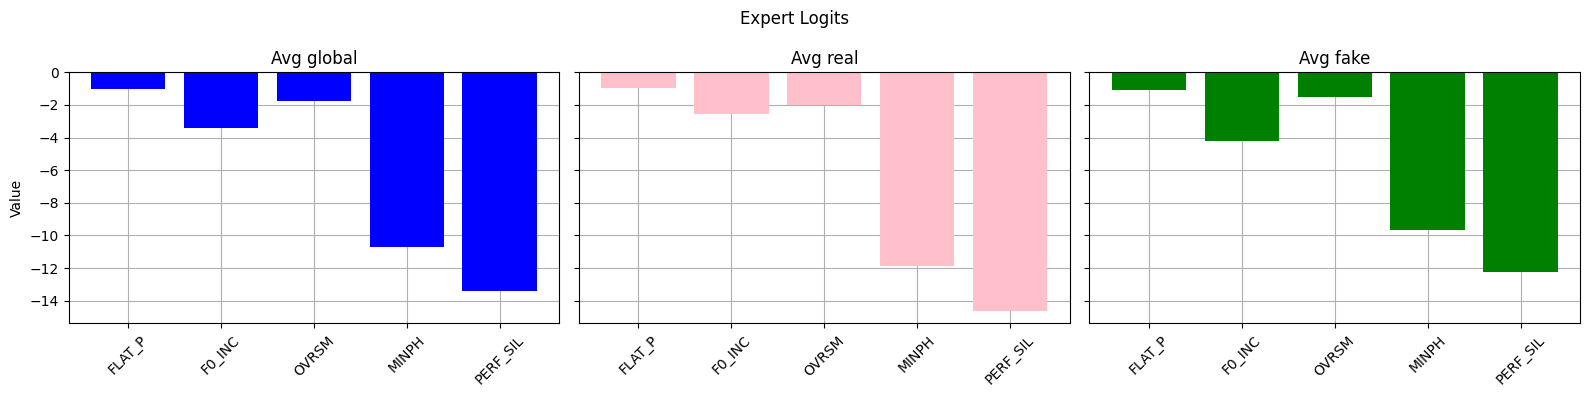

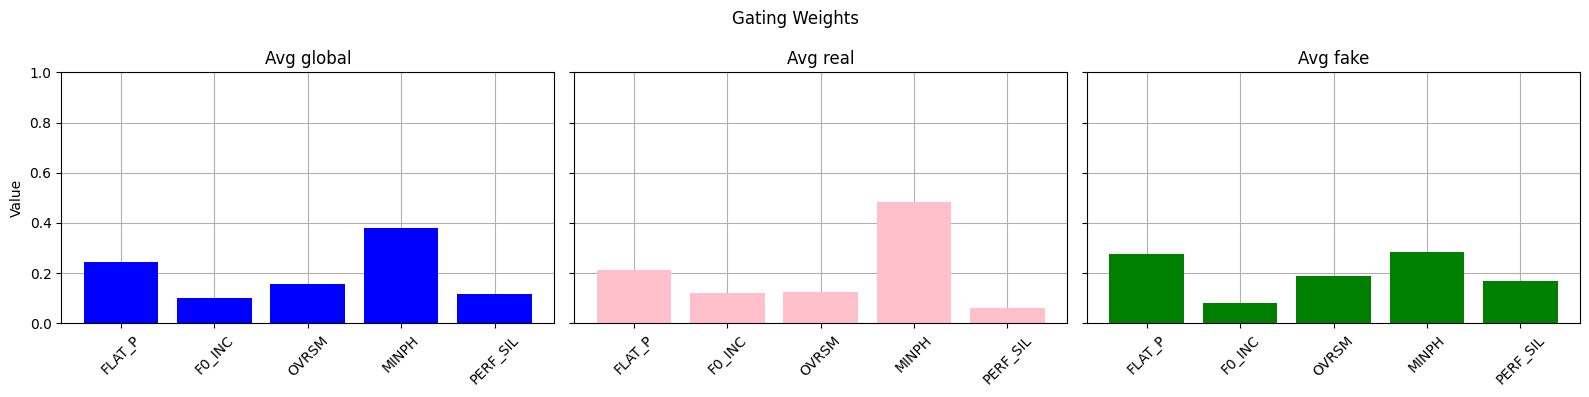

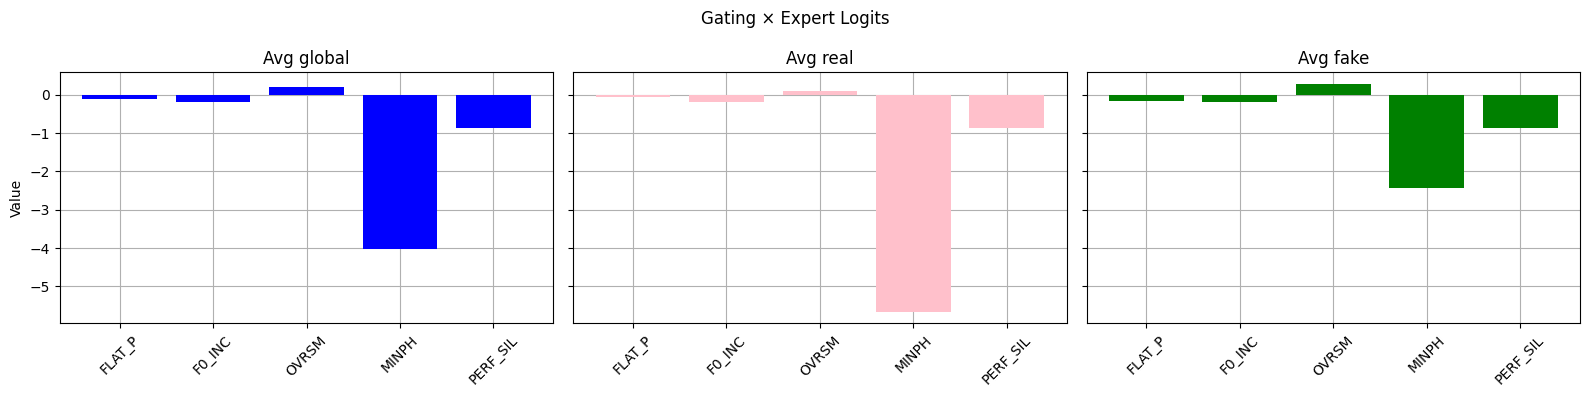

([array([ -1.0326198,  -3.4139035,  -1.7528214, -10.733881 , -13.418935 ],
        dtype=float32),
  array([ -0.95719194,  -2.581759  ,  -2.0011375 , -11.859442  ,
         -14.65566   ], dtype=float32),
  array([ -1.1055757,  -4.218799 ,  -1.5126287,  -9.645106 , -12.222815 ],
        dtype=float32)],
 [array([0.24603815, 0.10000956, 0.15807892, 0.38064542, 0.11522928],
        dtype=float32),
  array([0.2129314 , 0.11999429, 0.1256391 , 0.48201254, 0.05942139],
        dtype=float32),
  array([0.2780607 , 0.0806788 , 0.18945734, 0.2825929 , 0.16921103],
        dtype=float32)],
 [array([-0.10658795, -0.18869424,  0.19376412, -4.0256343 , -0.87091666],
        dtype=float32),
  array([-0.04607253, -0.18198504,  0.09584545, -5.6677527 , -0.8696824 ],
        dtype=float32),
  array([-0.16512232, -0.1951842 ,  0.28847766, -2.4372578 , -0.8721067 ],
        dtype=float32)])

In [19]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "frozen_5_exp_wxL_no_temp"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

# Best model - per generator analysis

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 32.87%, EER: 62.49%

MoE Performance:
AUC: 91.09%, EER: 16.90%
Loaded 1898 samples
Real mean score: -6.8503
Fake mean score: -0.3601



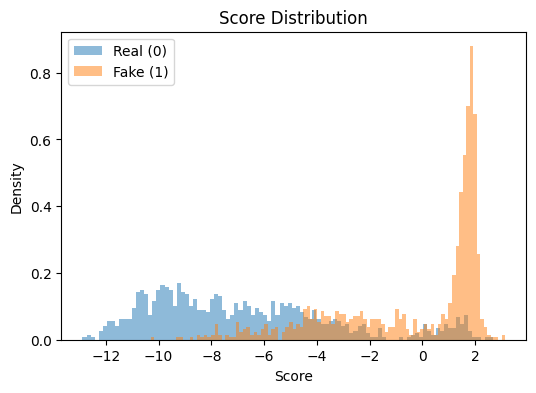

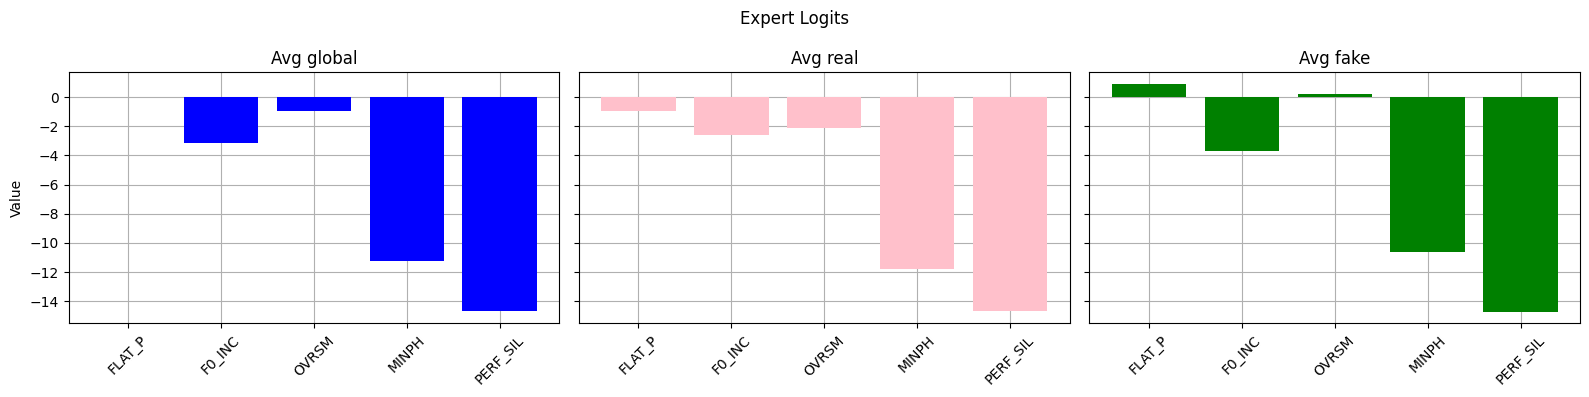

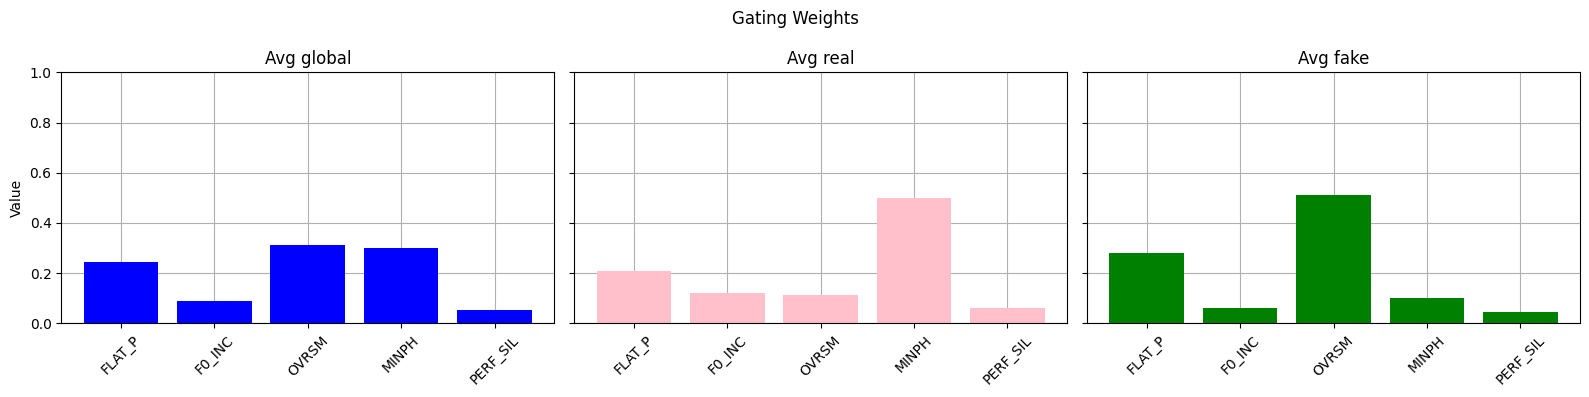

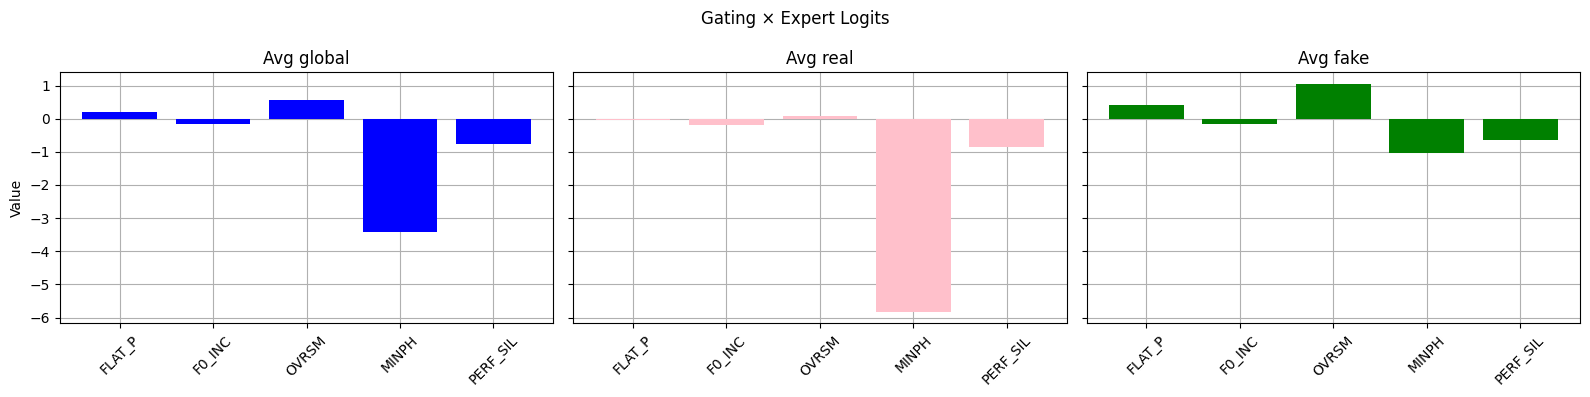

-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 61.48%, EER: 44.21%

MoE Performance:
AUC: 57.83%, EER: 47.93%
Loaded 1926 samples
Real mean score: -6.8503
Fake mean score: -5.4697



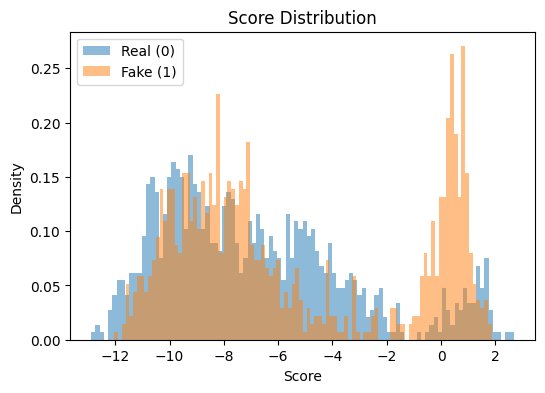

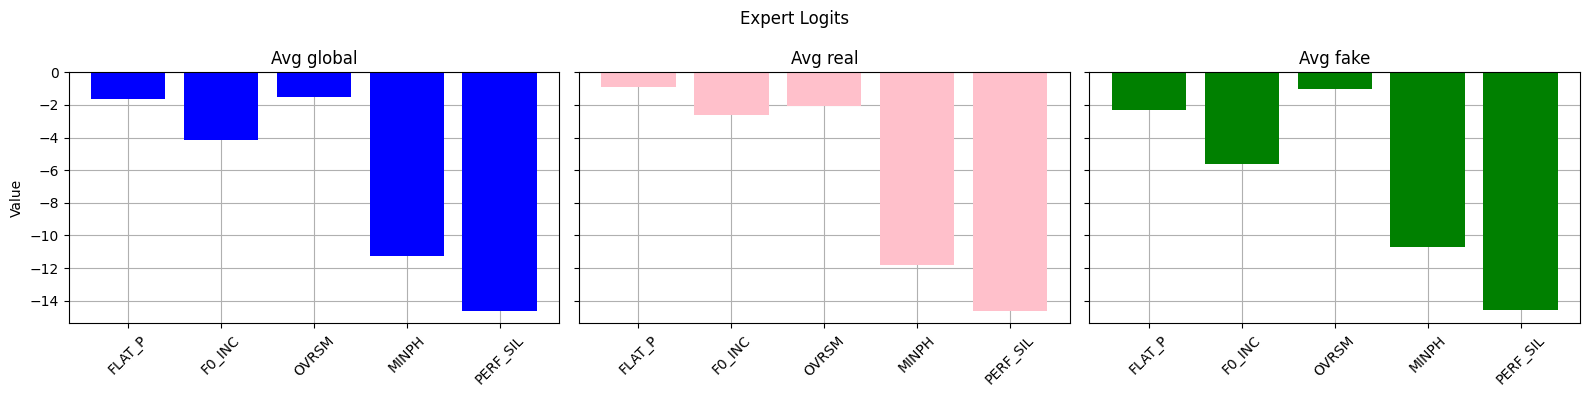

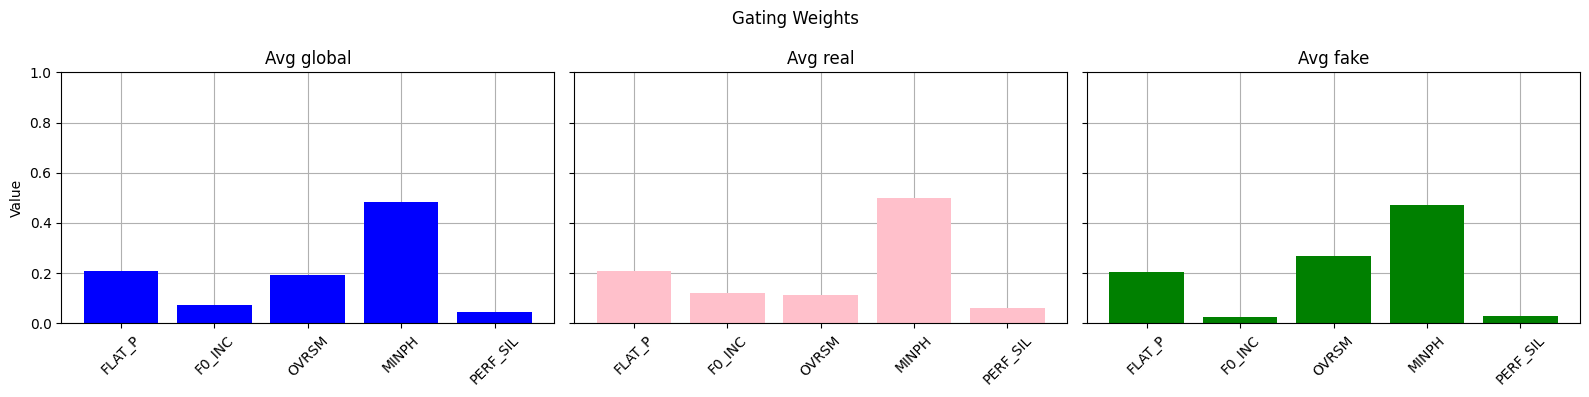

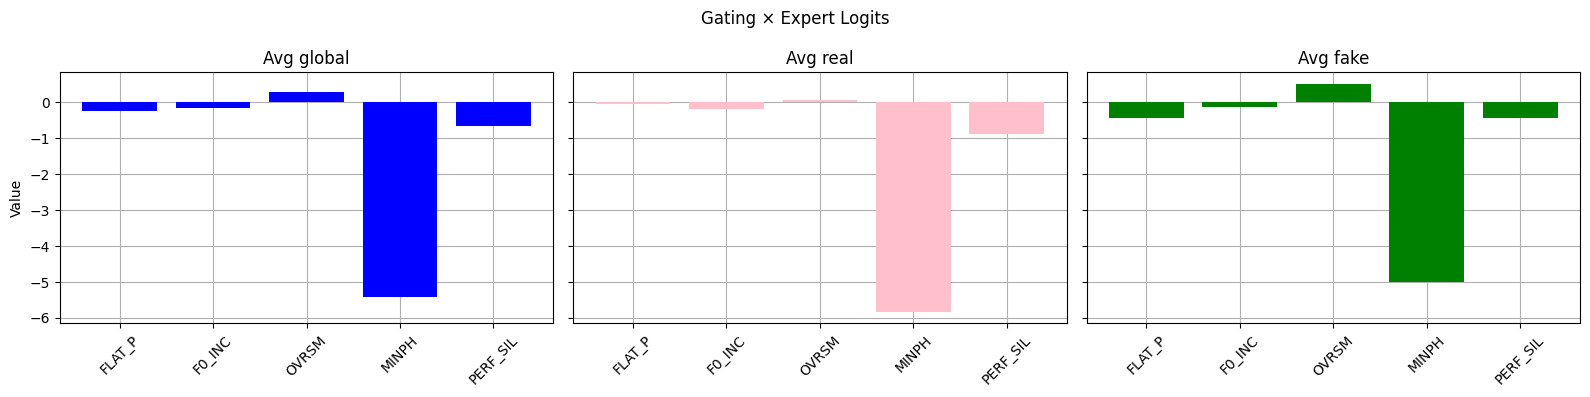

-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 76.86%, EER: 30.71%

MoE Performance:
AUC: 68.12%, EER: 38.79%
Loaded 1931 samples
Real mean score: -6.8503
Fake mean score: -4.5875



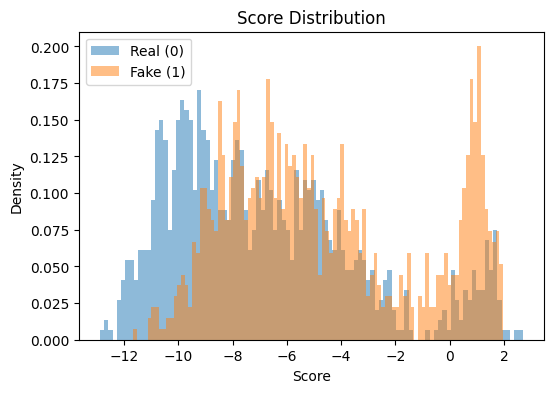

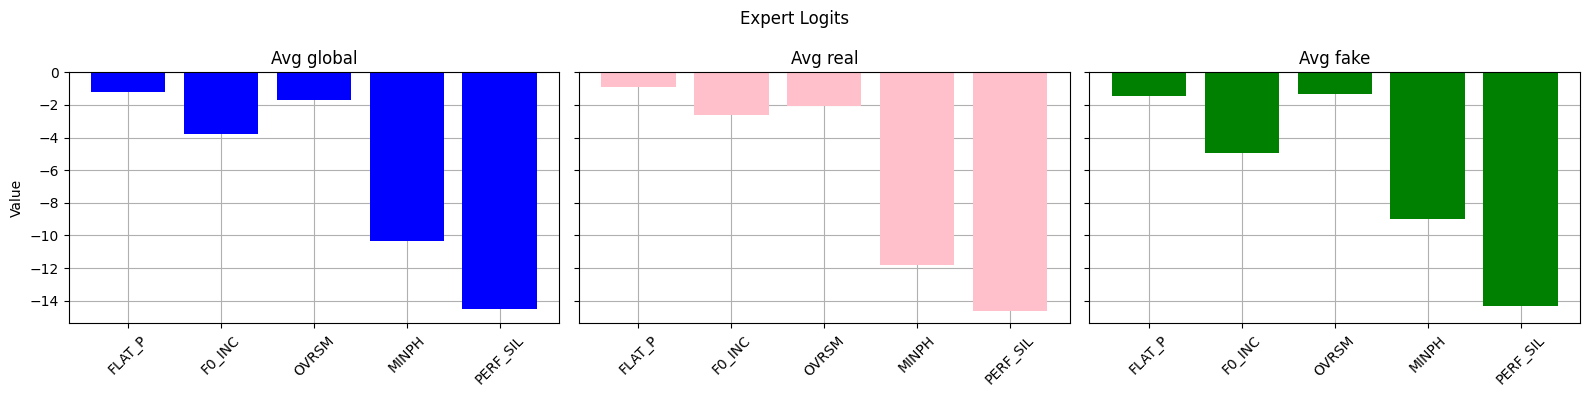

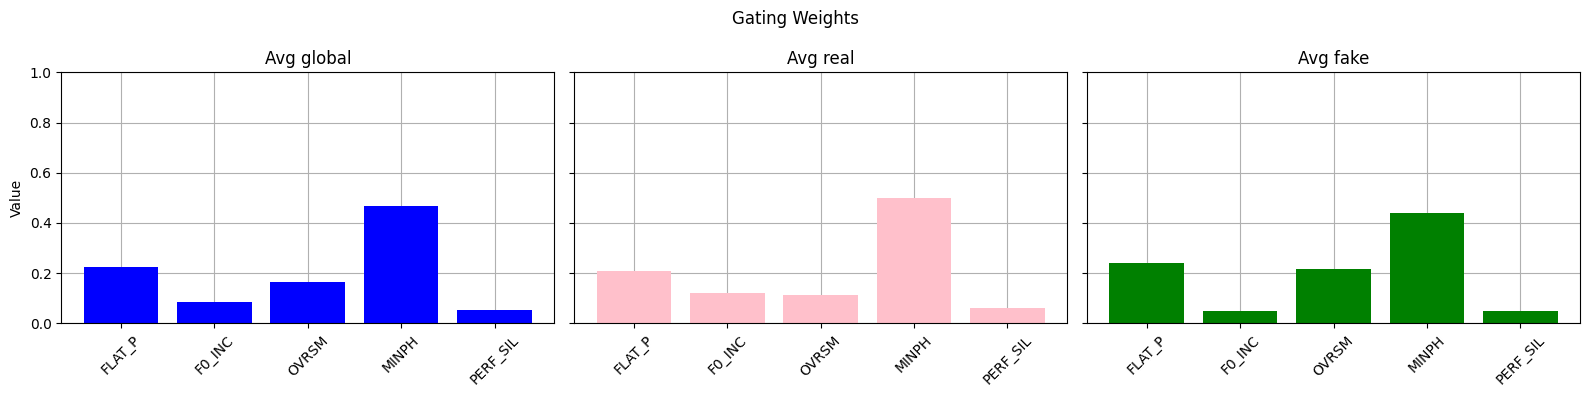

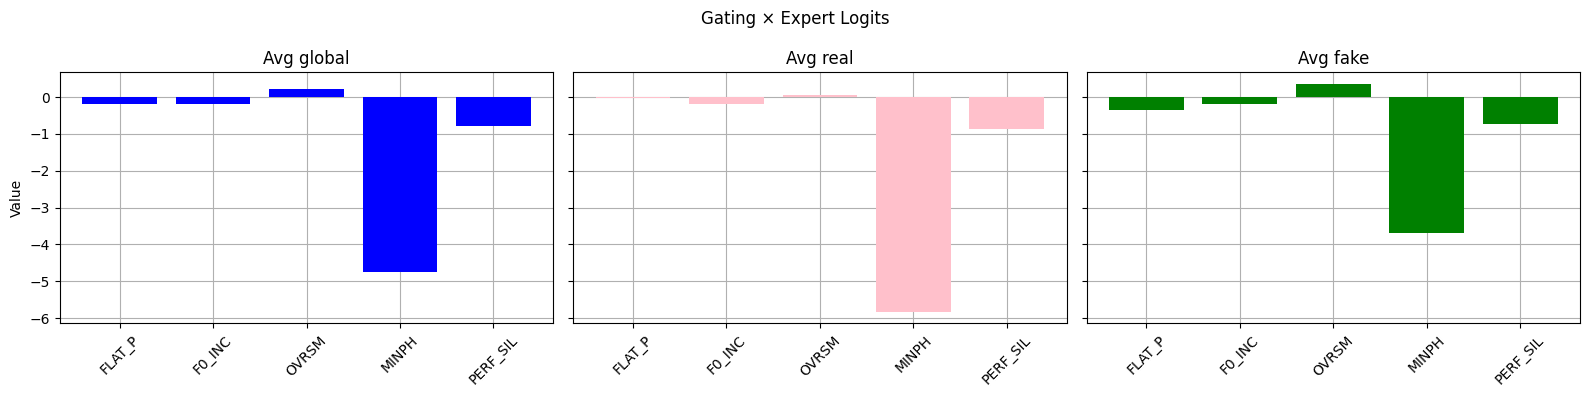

-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 74.05%, EER: 34.22%

MoE Performance:
AUC: 81.30%, EER: 25.40%
Loaded 1880 samples
Real mean score: -6.8503
Fake mean score: -2.8137



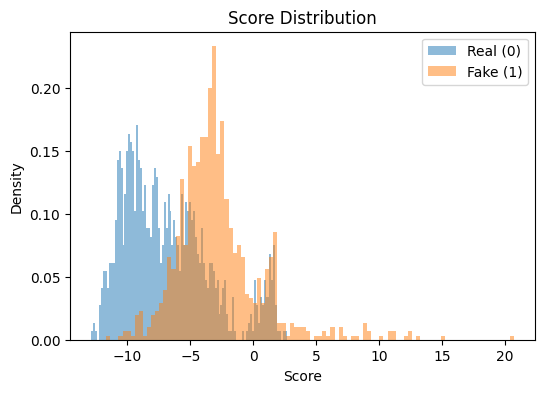

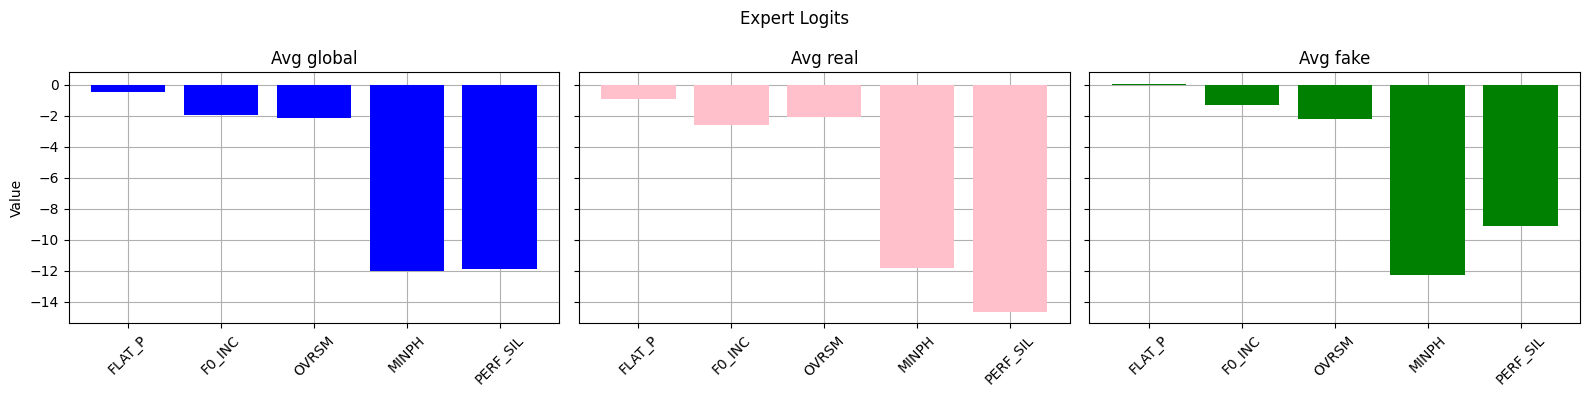

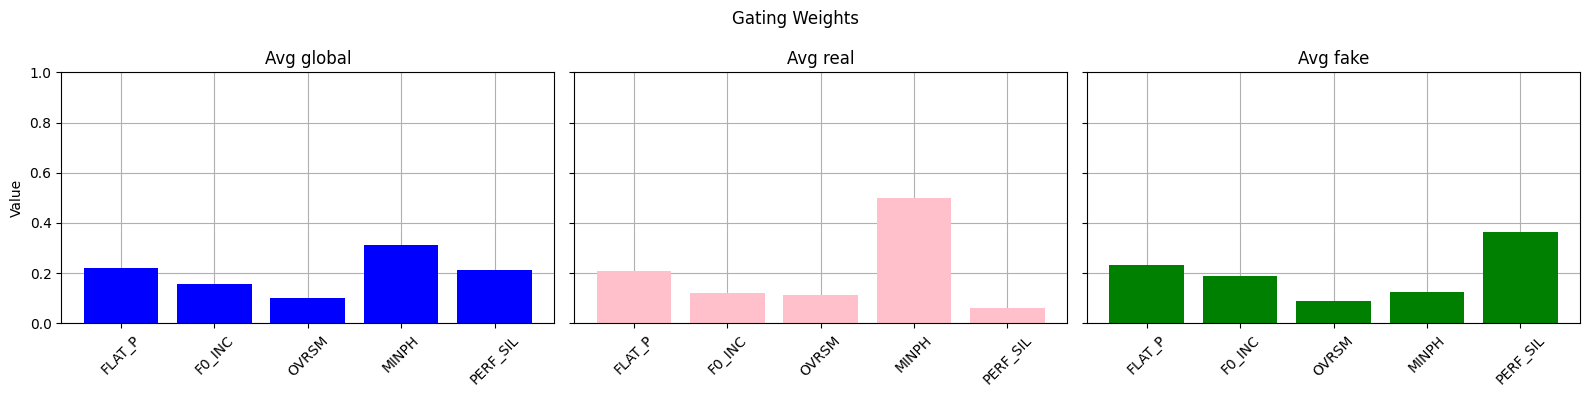

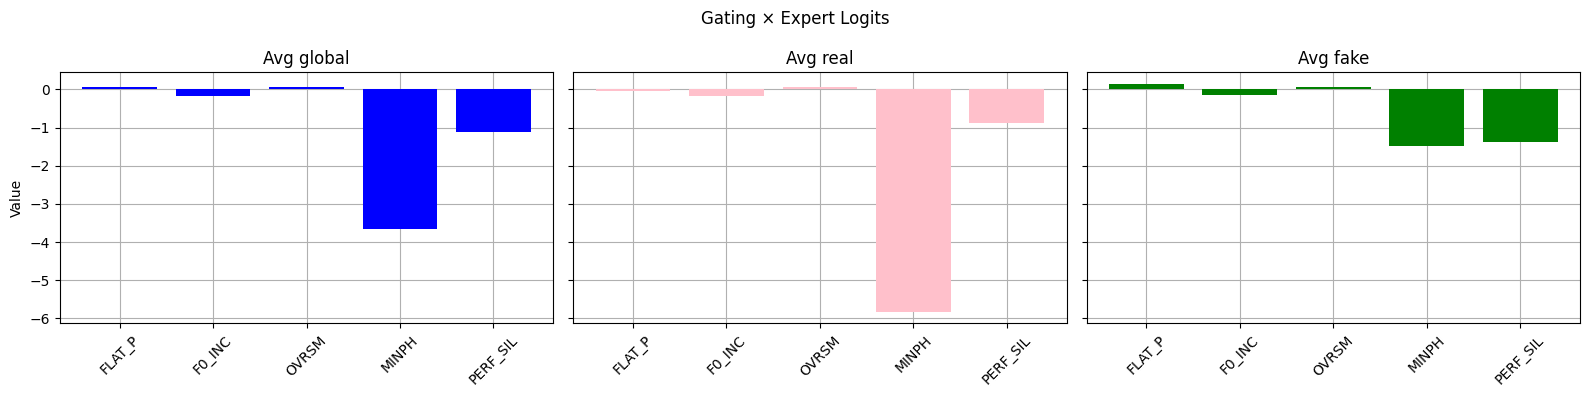

-----------------------------------
A07

Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 31.38%, EER: 64.08%

MoE Performance:
AUC: 69.04%, EER: 37.09%
Loaded 1940 samples
Real mean score: -6.8503
Fake mean score: -4.9709



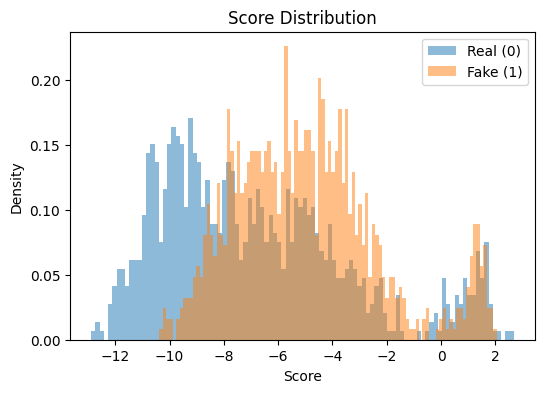

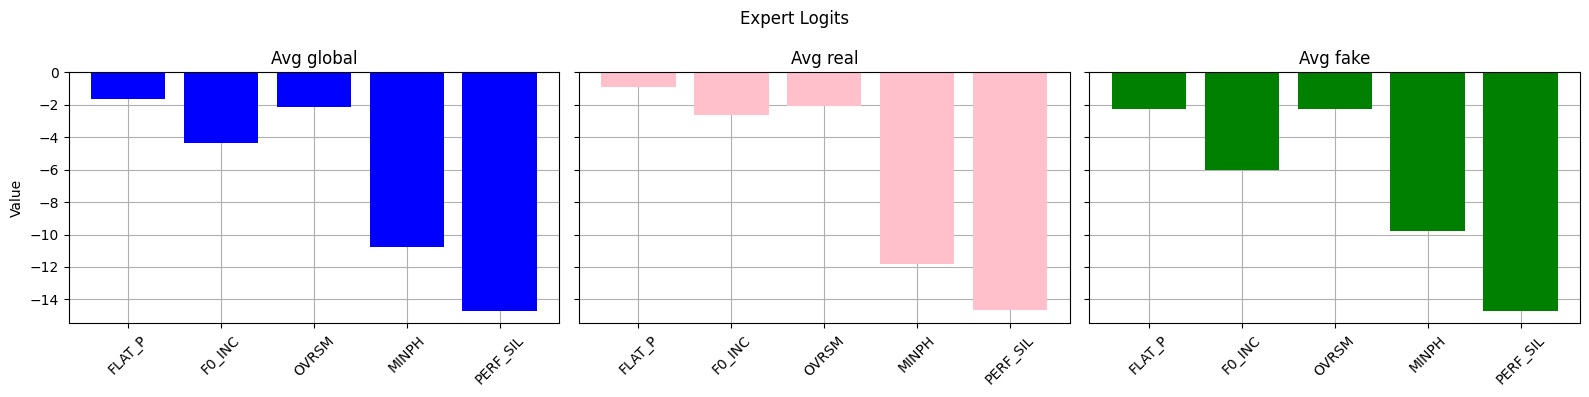

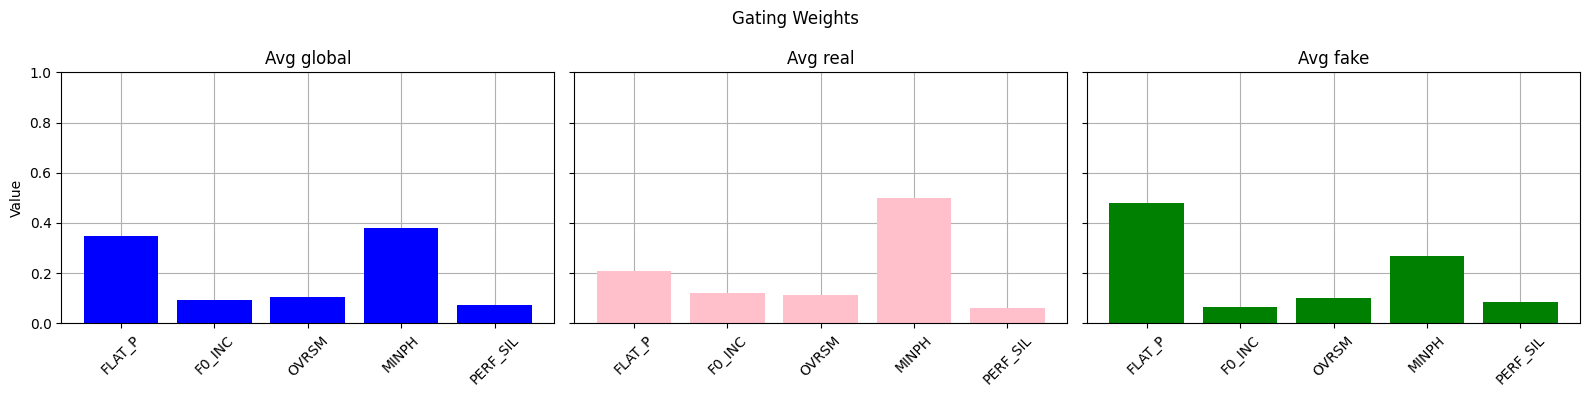

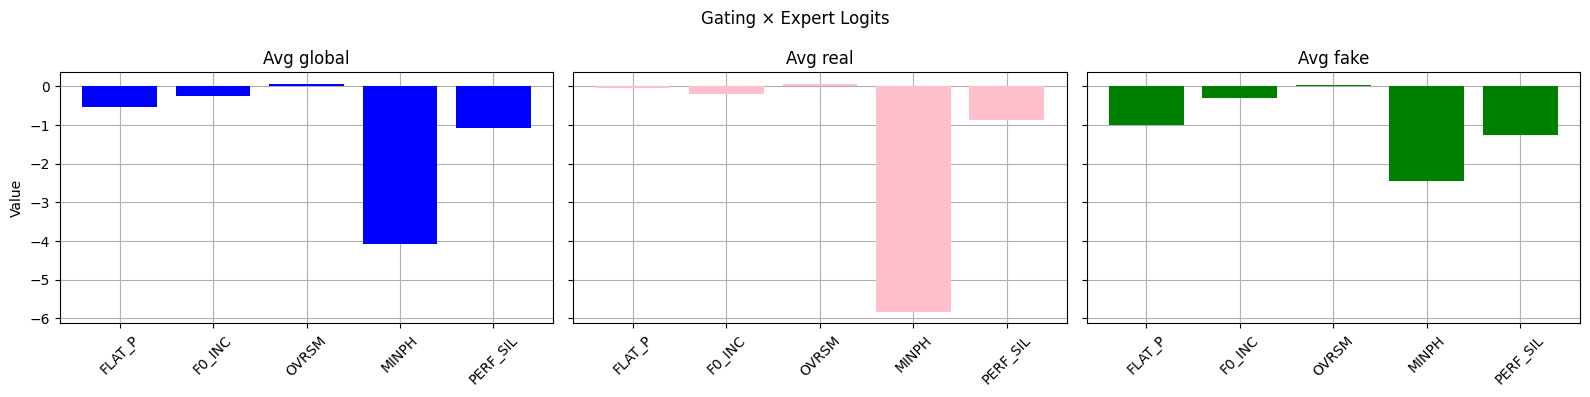

-----------------------------------
A08

Individual Experts' Performance:
AUC: 63.52%, EER: 39.64%
AUC: 26.31%, EER: 67.91%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 94.18%, EER: 11.16%

MoE Performance:
AUC: 78.44%, EER: 29.65%
Loaded 1933 samples
Real mean score: -6.8503
Fake mean score: -3.4237



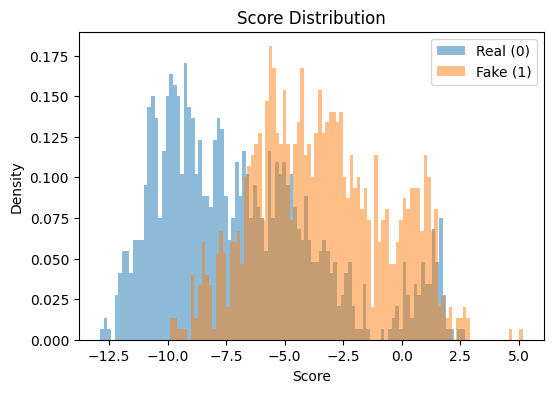

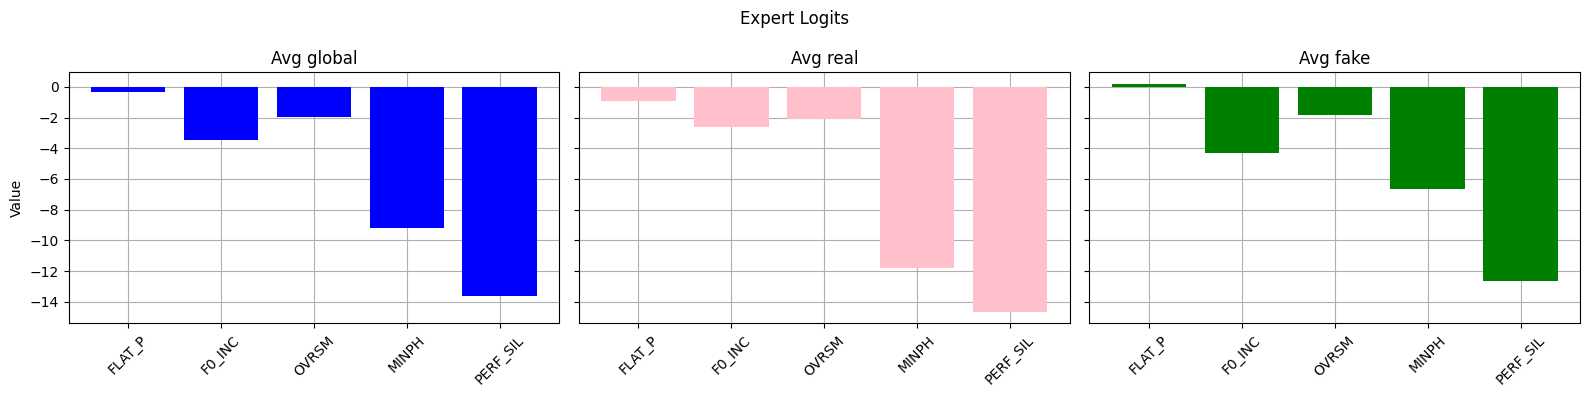

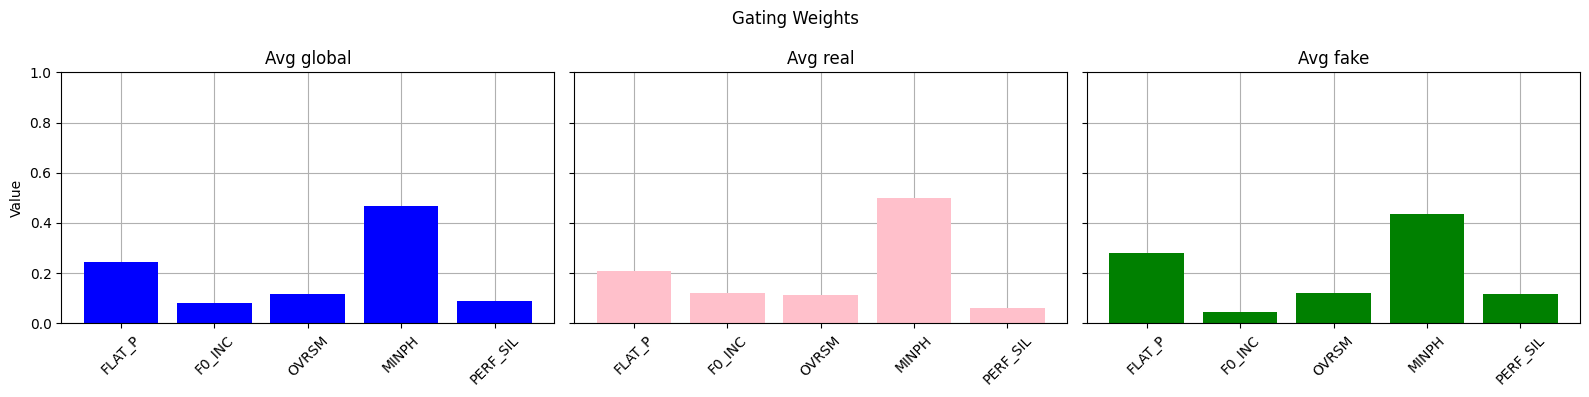

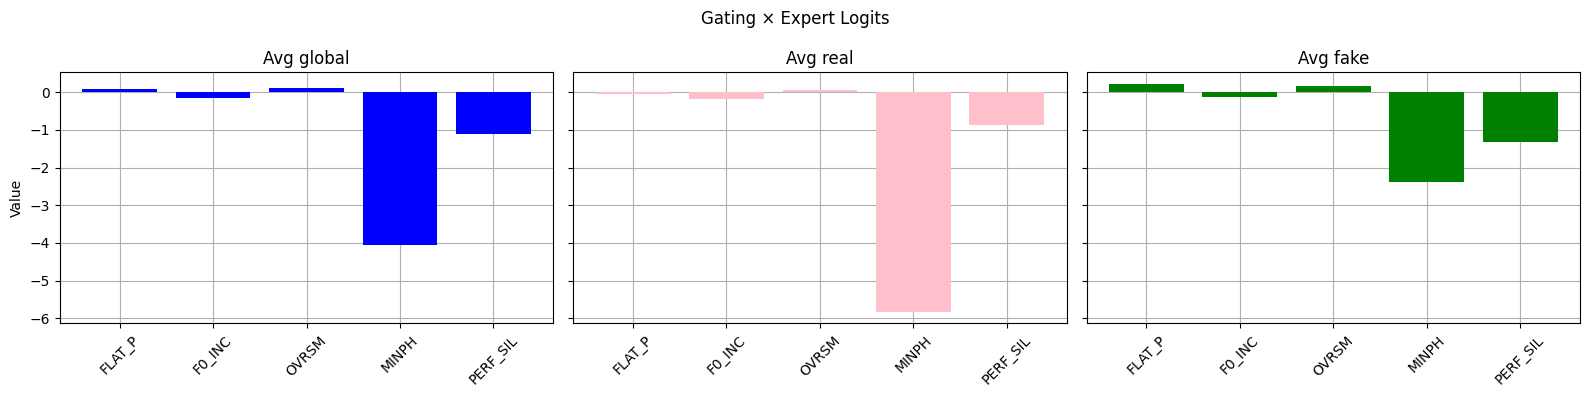

-----------------------------------
A09

Individual Experts' Performance:
AUC: 22.77%, EER: 70.46%
AUC: 15.13%, EER: 75.77%
AUC: 74.59%, EER: 33.90%
AUC: 98.97%, EER: 4.68%
AUC: 85.03%, EER: 22.00%

MoE Performance:
AUC: 87.24%, EER: 20.30%
Loaded 1939 samples
Real mean score: -6.8503
Fake mean score: 0.6652



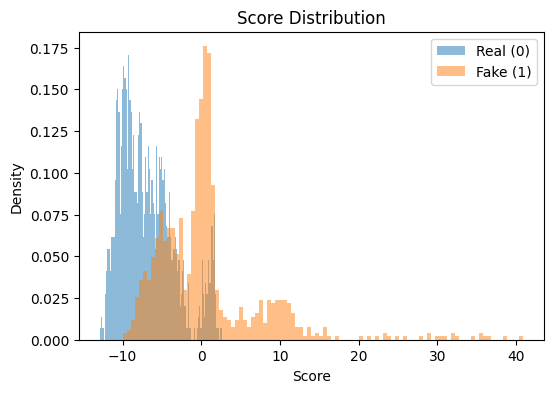

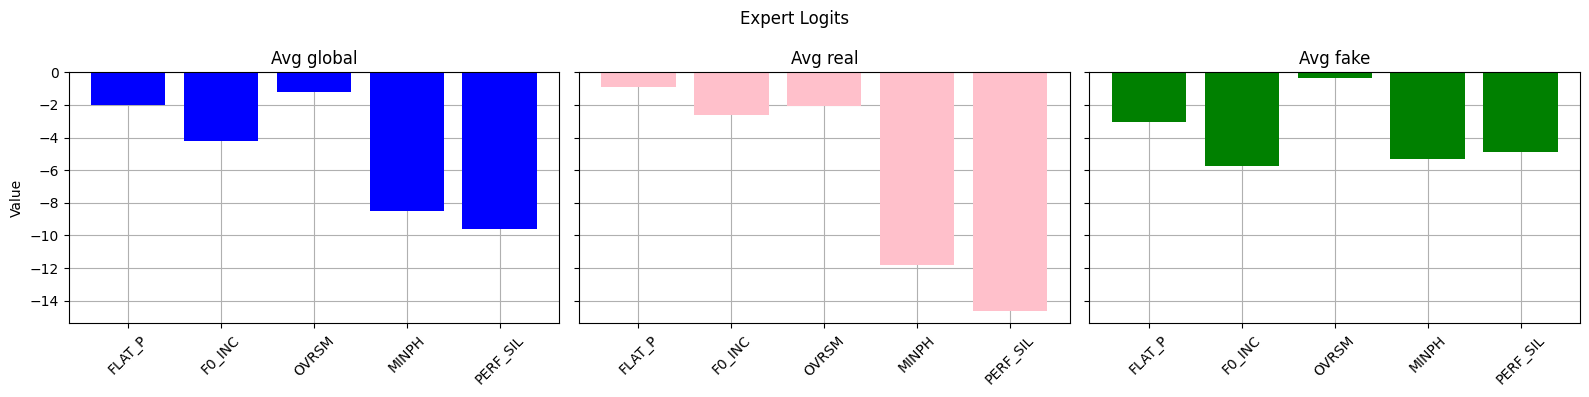

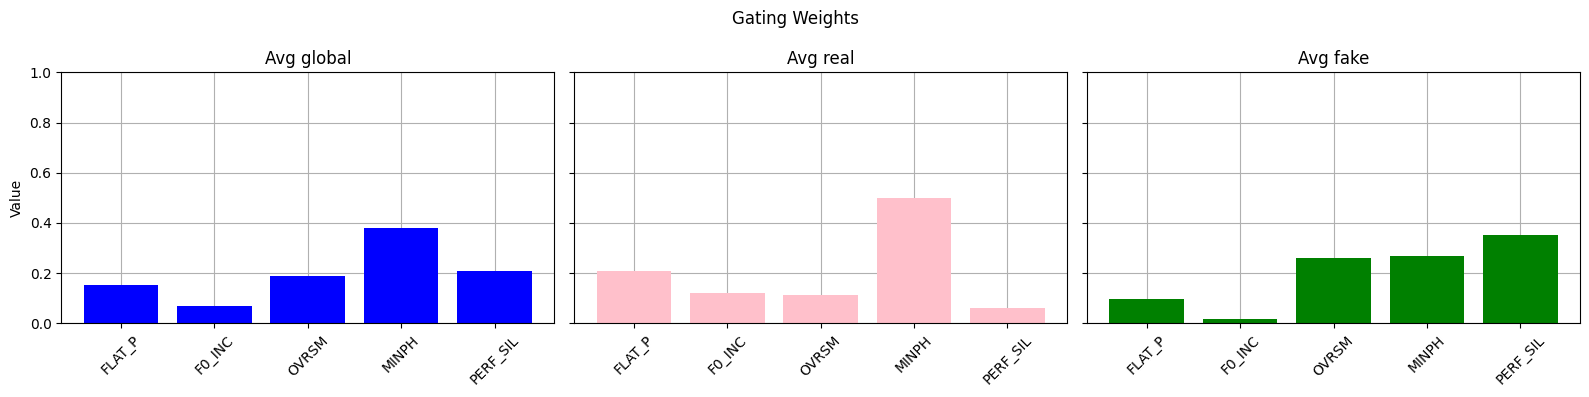

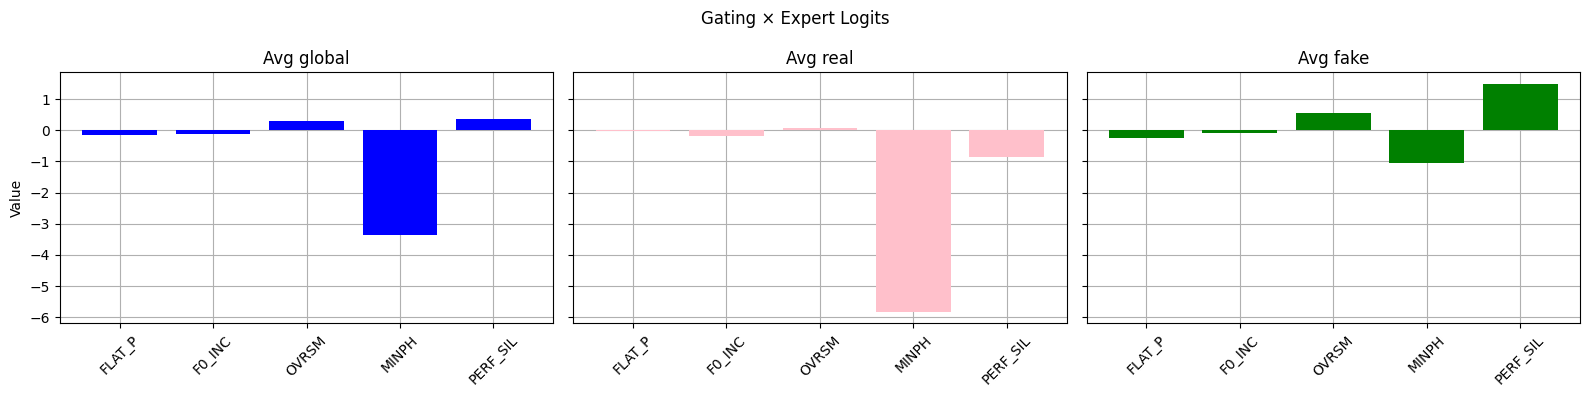

-----------------------------------
A10

Individual Experts' Performance:
AUC: 50.32%, EER: 48.99%
AUC: 38.14%, EER: 58.24%
AUC: 41.40%, EER: 57.60%
AUC: 68.30%, EER: 36.03%
AUC: 46.59%, EER: 51.75%

MoE Performance:
AUC: 69.93%, EER: 35.71%
Loaded 1898 samples
Real mean score: -6.8503
Fake mean score: -4.6613



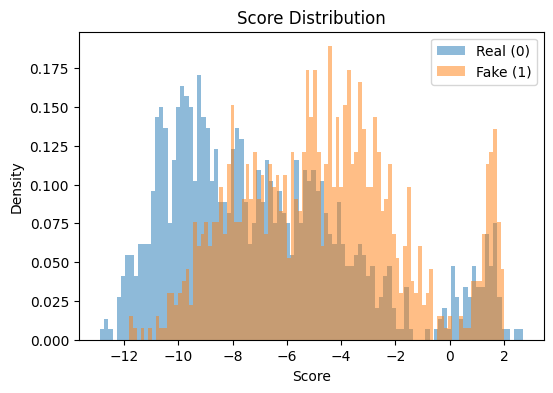

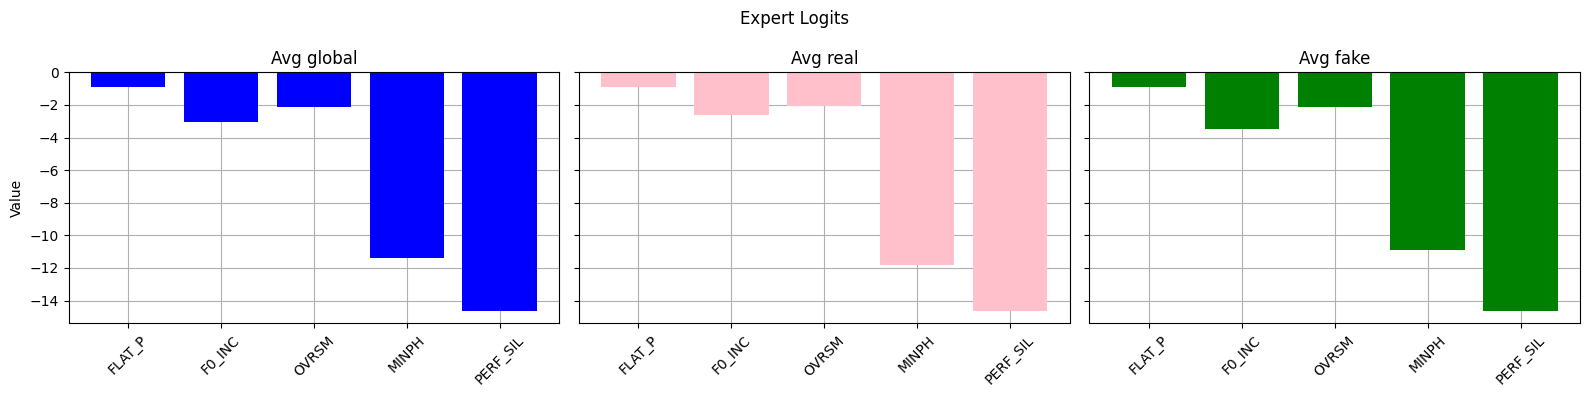

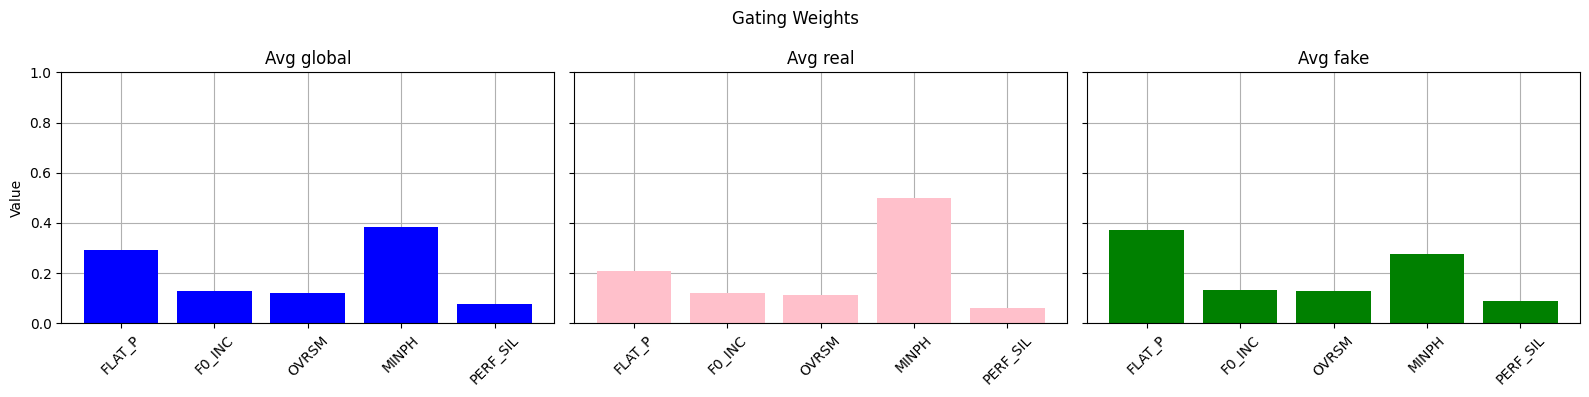

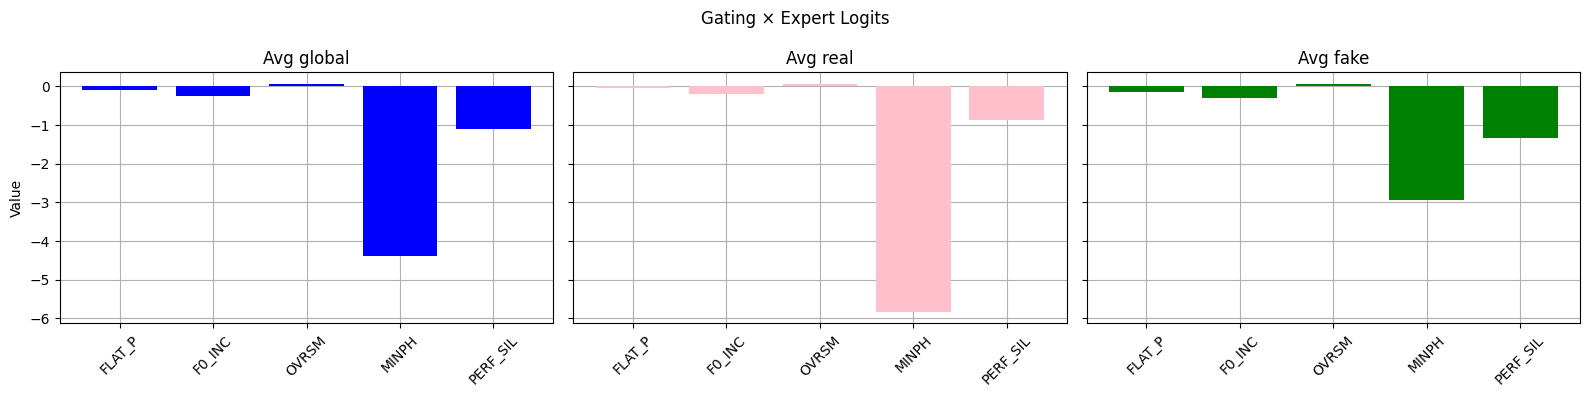

-----------------------------------
A11

Individual Experts' Performance:
AUC: 46.13%, EER: 52.39%
AUC: 35.13%, EER: 59.19%
AUC: 45.27%, EER: 56.11%
AUC: 78.28%, EER: 29.33%
AUC: 56.42%, EER: 46.76%

MoE Performance:
AUC: 71.45%, EER: 35.49%
Loaded 1902 samples
Real mean score: -6.8503
Fake mean score: -4.3300



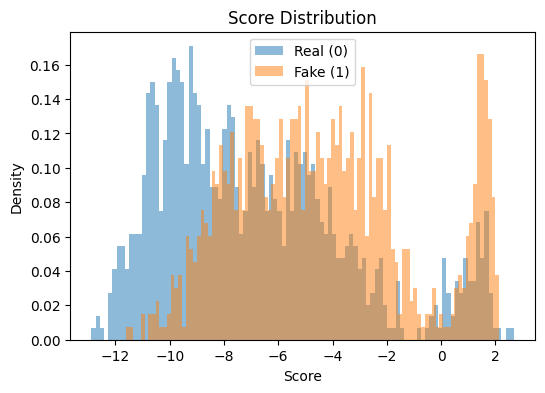

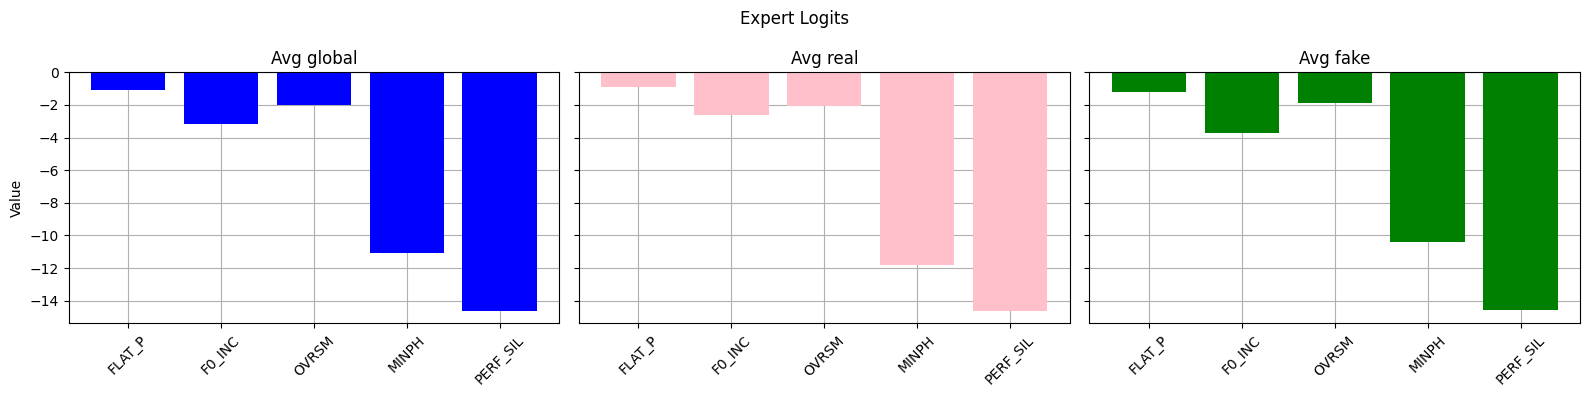

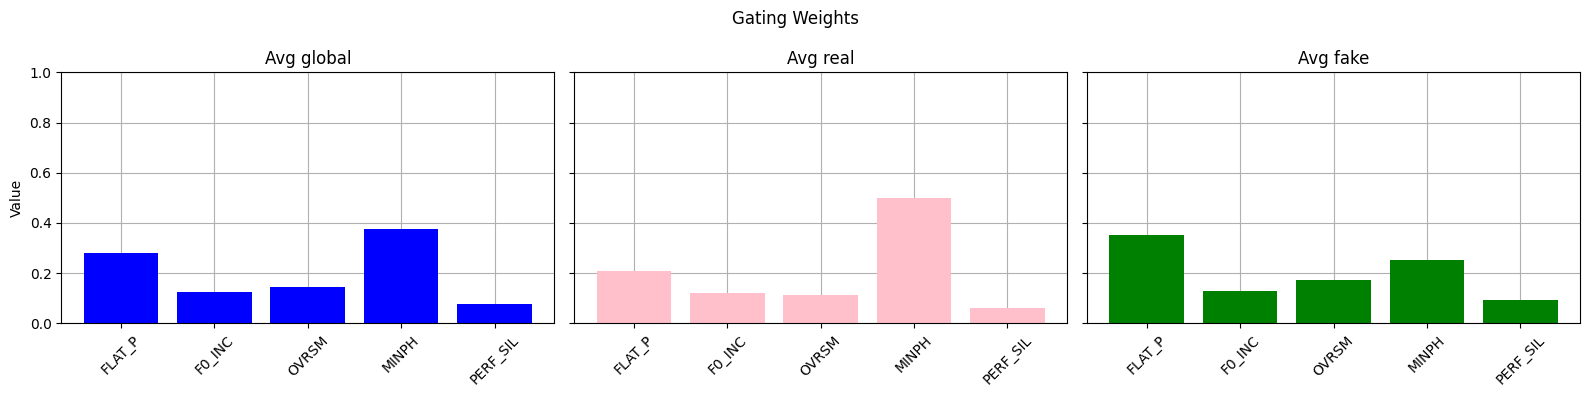

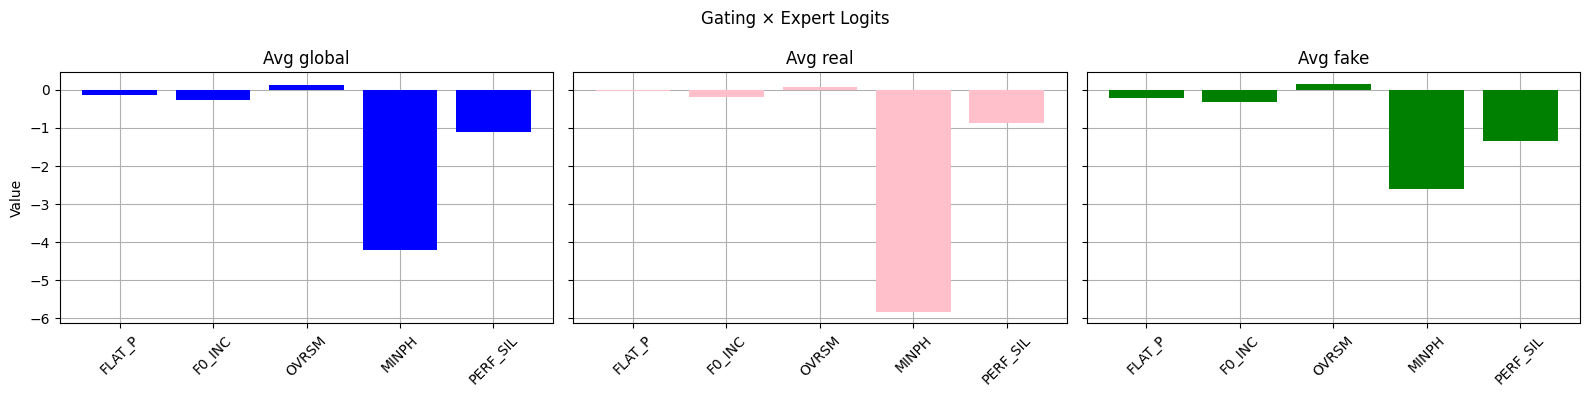

-----------------------------------
A12

Individual Experts' Performance:
AUC: 52.39%, EER: 48.14%
AUC: 39.70%, EER: 56.64%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 83.42%, EER: 23.38%

MoE Performance:
AUC: 74.22%, EER: 32.94%
Loaded 1876 samples
Real mean score: -6.8503
Fake mean score: -3.5408



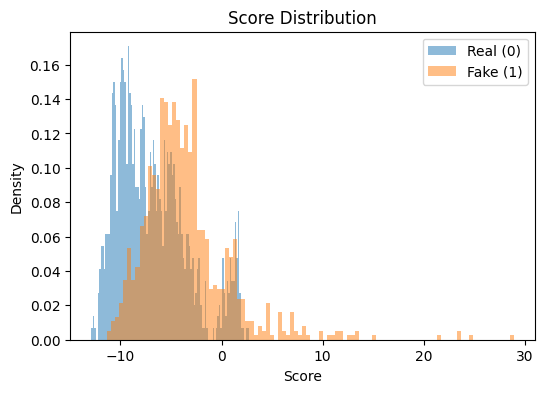

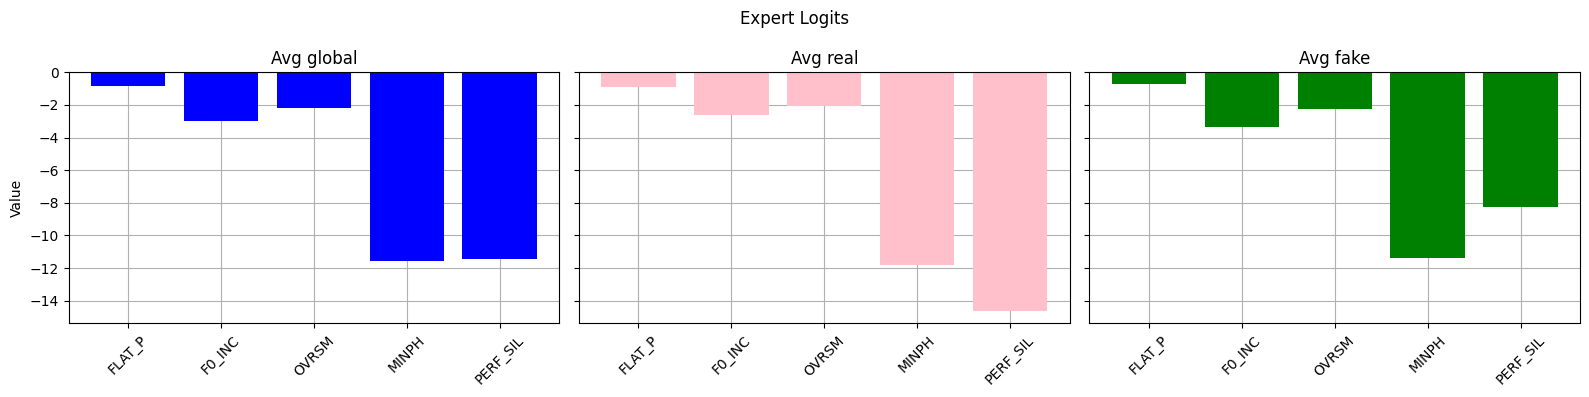

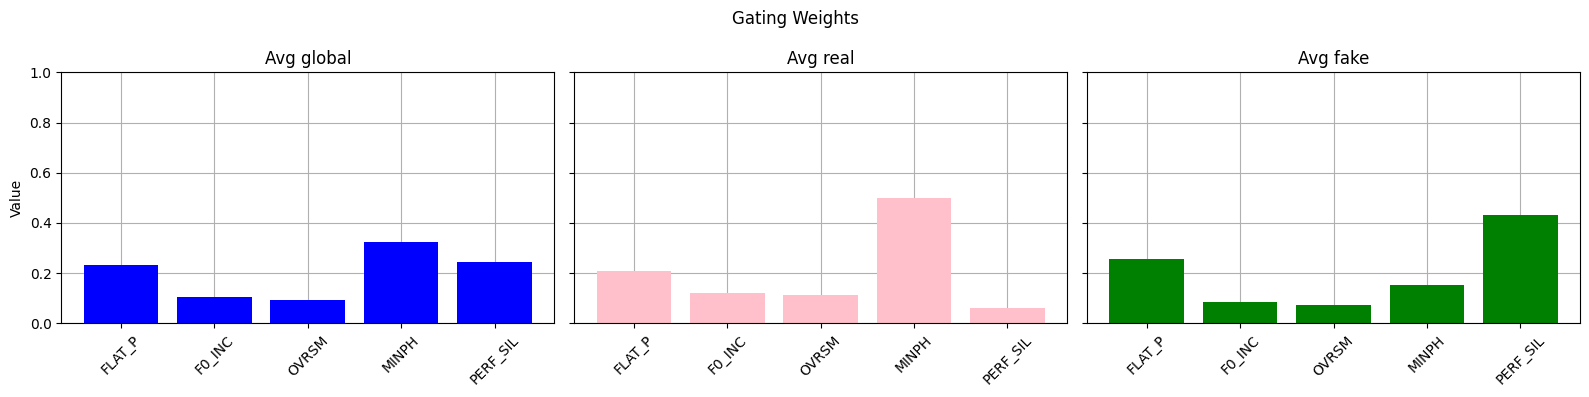

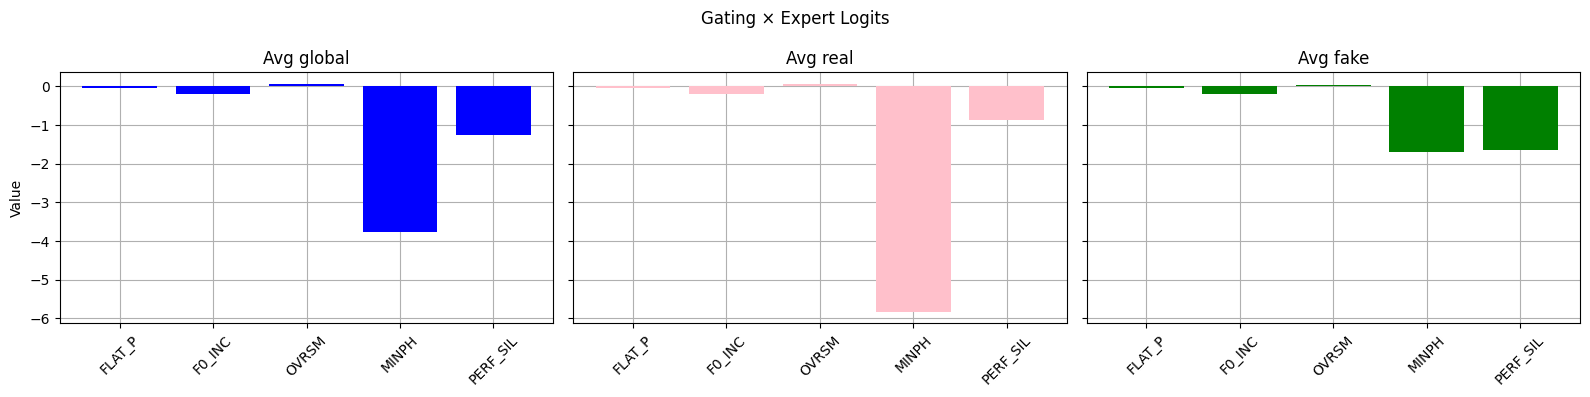

-----------------------------------


In [20]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "frozen_5_exp_wxL_no_temp"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True, plot=True)
    print("-----------------------------------")

# Further diagnosis


Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 31.38%, EER: 64.08%

MoE Performance:
AUC: 69.04%, EER: 37.09%


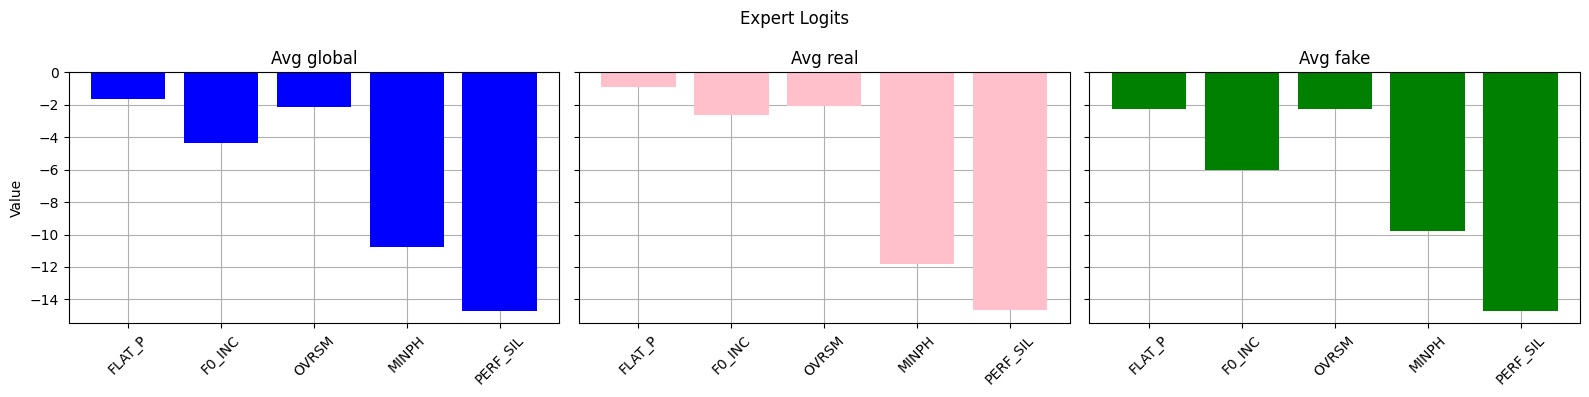

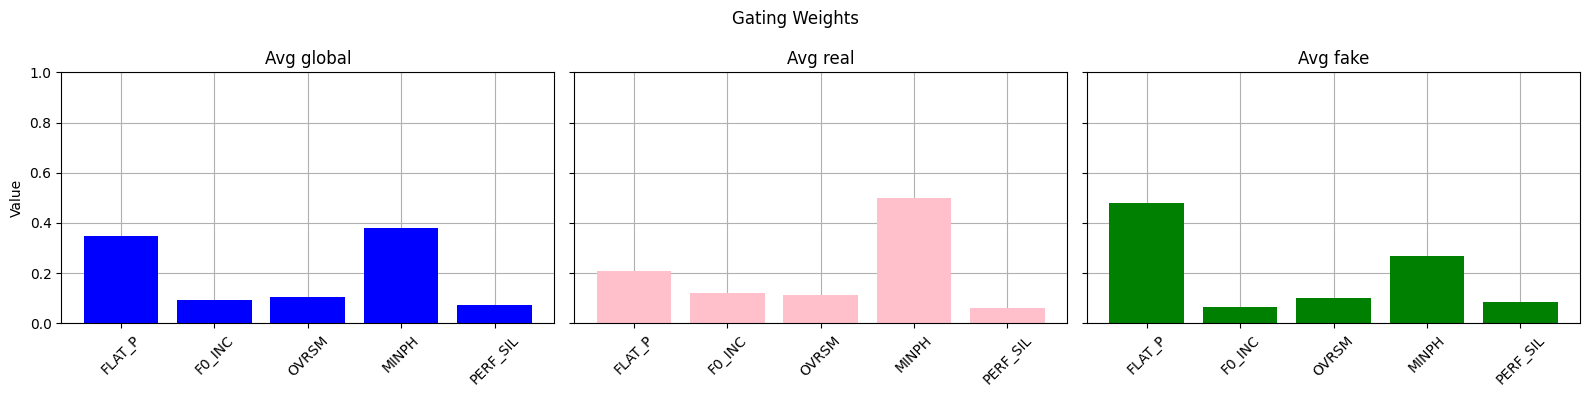

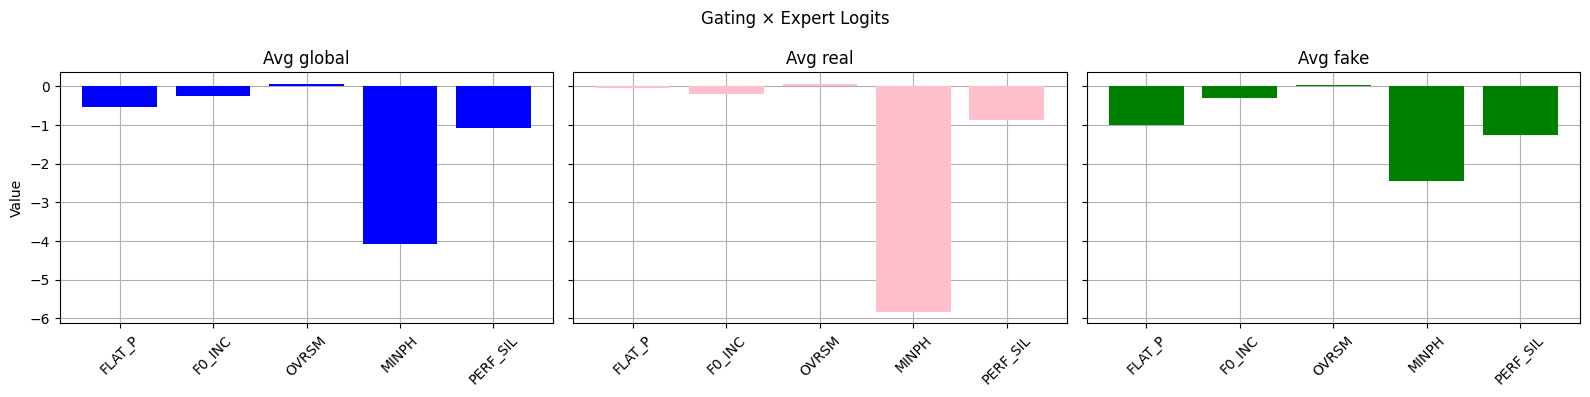


Average Expert Stats + Gate Weights
Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F
-----------------------------------------------------------------------------------------------
  0    |  -1.626269 |  -0.925251 |  -2.286585 |  -1.361334 |  0.2094 |  0.4797
  1    |  -4.378347 |  -2.612678 |  -6.041510 |  -3.428833 |  0.1210 |  0.0667
  2    |  -2.159600 |  -2.084624 |  -2.230222 |  -0.145597 |  0.1118 |  0.1003
  3    | -10.774311 | -11.801059 |  -9.807181 |   1.993877 |  0.4985 |  0.2683
  4    | -14.697298 | -14.654348 | -14.737752 |  -0.083404 |  0.0593 |  0.0849


In [22]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/A07"
model_name = "frozen_5_exp_wxL_no_temp"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
e, g, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, plot=True)

print("\nAverage Expert Stats + Gate Weights")
print("Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F")
print("-" * 95)

for j in range(len(e[0])):
    overall = e[0][j]
    real = e[1][j]
    fake = e[2][j]
    delta = fake - real

    gate_real = g[1][j]
    gate_fake = g[2][j]

    print(f"{j:^6} | "
          f"{overall:10.6f} | "
          f"{real:10.6f} | "
          f"{fake:10.6f} | "
          f"{delta:10.6f} | "
          f"{gate_real:7.4f} | "
          f"{gate_fake:7.4f}")

In [86]:
import librosa
import torchaudio
import torch
import IPython.display as ipd

def plot_mel_groups(base_path, group1_ids, group2_ids):
    group1_ids = np.random.choice(group1_ids, size=min(3, len(group1_ids)), replace=False)
    group2_ids = np.random.choice(group2_ids, size=min(3, len(group2_ids)), replace=False)

    mel_transform = torchaudio.transforms.MelSpectrogram(
        sample_rate=16000,
        n_fft=1024,
        hop_length=256,
        n_mels=128
    )

    amp_to_db = torchaudio.transforms.AmplitudeToDB()

    fig, axes = plt.subplots(2, 5, figsize=(20, 6))

    all_groups = [group1_ids, group2_ids]

    for row, group in enumerate(all_groups):
        for col in range(5):
            axes[row, col].axis("off")  # turn off by default

            if col >= len(group):
                continue

            utt_id = group[col]
            wav_path = os.path.join(base_path, utt_id + ".flac")

            waveform, sr = librosa.load(wav_path, sr=16000)
            waveform = torch.tensor(waveform).unsqueeze(0)

            mel = mel_transform(waveform)
            mel_db = amp_to_db(mel)

            axes[row, col].imshow(
                mel_db.squeeze().numpy(),
                aspect="auto",
                origin="lower"
            )
            axes[row, col].set_title(utt_id, fontsize=8)
            axes[row, col].axis("off")

            print(f"\nPlaying: {utt_id}")
            display(ipd.Audio(waveform, rate=sr))

    plt.tight_layout()
    plt.show()


In [93]:
scores_path_A10 = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/A10/frozen_5_exp_wxL_no_temp/scores.txt"

ids_A10 = []
scores_A10 = []
labels_A10 = []

with open(scores_path_A10, 'r') as fh:
    for line in fh:
        parts = line.strip().split()
        if len(parts) != 3:
            continue  

        utt_id, score, label = parts
        ids_A10.append(utt_id)
        scores_A10.append(float(score.strip("[]")))
        labels_A10.append(int(label))

ids_A10 = np.array(ids_A10)
scores_A10 = np.array(scores_A10)
labels_A10 = np.array(labels_A10)

np.random.seed(42)

mask_pos = (scores_A10 >= 1) & (scores_A10 <= 2)
mask_neg = (scores_A10 >= -10) & (scores_A10 <= -8)

ids_pos = ids_A10[mask_pos]
ids_neg = ids_A10[mask_neg]

print("Available in [1,2]:", len(ids_pos))
print("Available in [-10,-8]:", len(ids_neg))

sample_pos = np.random.choice(ids_pos, size=100, replace=False)
sample_neg = np.random.choice(ids_neg, size=100, replace=False)

sample_pos_filtered = [utt for utt in sample_pos if utt.startswith("LA_E")]
sample_neg_filtered = [utt for utt in sample_neg if utt.startswith("LA_E")]

print("Remaining in [1,2] after LA_E filter:", len(sample_pos_filtered))
print("Remaining in [-10,-8] after LA_E filter:", len(sample_neg_filtered))


Available in [1,2]: 119
Available in [-10,-8]: 365
Remaining in [1,2] after LA_E filter: 87
Remaining in [-10,-8] after LA_E filter: 65



Playing: LA_E_2497100



Playing: LA_E_7042652



Playing: LA_E_5537699



Playing: LA_E_7769321



Playing: LA_E_9617604



Playing: LA_E_9630899


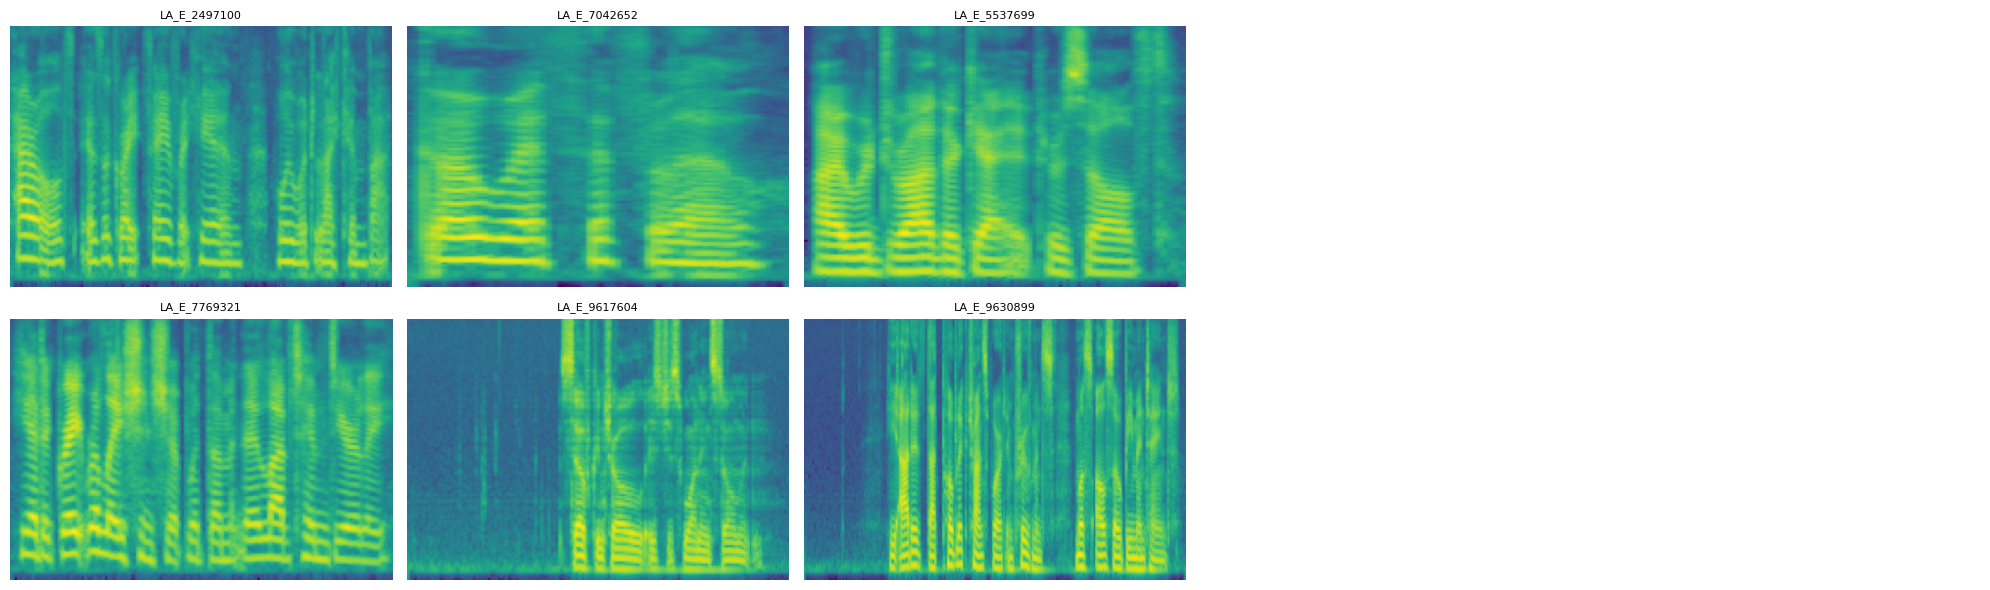

In [98]:
plot_mel_groups(
    base_path="/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac",
    group1_ids=sample_pos_filtered,
    group2_ids=sample_neg_filtered
)